In [9]:
import matplotlib.pyplot as plt
import tensorflow as tf
import pandas as pd
from tensorflow.keras.models import Sequential
from sklearn.model_selection import train_test_split
from tensorflow.keras.layers import Dense,Flatten,Input
from tensorflow.keras.optimizers import Adam

In [10]:
data=pd.read_csv('cifar-10.csv')
y=data['label'].values
x=data.drop('label',axis=1).values
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [11]:
x_train=x_train/255.0
x_test=x_test/255.0

In [12]:
model=Sequential([Input(shape=(x_train.shape[1],)),
                 Dense(512,activation='relu'),
                 Dense(256,activation='relu'),
                 Dense(10,activation='softmax')])

In [13]:
model.compile(optimizer=Adam(learning_rate=0.001),
             loss='sparse_categorical_crossentropy',
             metrics=['accuracy'])

In [14]:
history=model.fit(x_train,y_train,epochs=11,batch_size=64,validation_data=(x_test,y_test))

Epoch 1/11
625/625 ━━━━━━━━━━━━━━━━━━━━ 20s 27ms/step - accuracy: 0.3143 - loss: 1.9122 - val_accuracy: 0.3546 - val_loss: 1.7797
Epoch 2/11
625/625 ━━━━━━━━━━━━━━━━━━━━ 15s 24ms/step - accuracy: 0.3813 - loss: 1.7194 - val_accuracy: 0.4005 - val_loss: 1.6569
Epoch 3/11
625/625 ━━━━━━━━━━━━━━━━━━━━ 15s 25ms/step - accuracy: 0.4218 - loss: 1.6163 - val_accuracy: 0.4071 - val_loss: 1.6540
Epoch 4/11
625/625 ━━━━━━━━━━━━━━━━━━━━ 15s 25ms/step - accuracy: 0.4475 - loss: 1.5558 - val_accuracy: 0.4497 - val_loss: 1.5417
Epoch 5/11
625/625 ━━━━━━━━━━━━━━━━━━━━ 15s 25ms/step - accuracy: 0.4656 - loss: 1.5122 - val_accuracy: 0.4427 - val_loss: 1.5608
Epoch 6/11
625/625 ━━━━━━━━━━━━━━━━━━━━ 15s 24ms/step - accuracy: 0.4717 - loss: 1.4806 - val_accuracy: 0.4536 - val_loss: 1.5337
Epoch 7/11
625/625 ━━━━━━━━━━━━━━━━━━━━ 15s 24ms/step - accuracy: 0.4830 - loss: 1.4507 - val_accuracy: 0.4665 - val_loss: 1.5018
Epoch 8/11
625/625 ━━━━━━━━━━━━━━━━━━━━ 15s 25ms/step - accuracy: 0.4938 - loss: 1.4219 - 

In [15]:
test_loss,test_accuracy=model.evaluate(x_test,y_test)
print(f"Test Loss:{test_loss:.4f}")
print(f"Test Accuracy:{test_accuracy*100:.2f}%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.4700 - loss: 1.4979
Test Loss:1.4979
Test Accuracy:47.00%


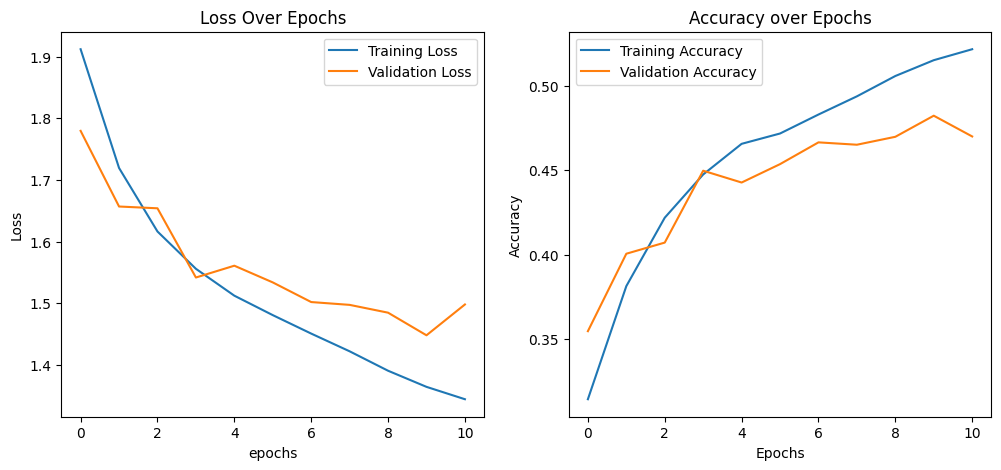

In [18]:
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.plot(history.history['loss'],label='Training Loss')
plt.plot(history.history['val_loss'],label='Validation Loss')
plt.title('Loss Over Epochs')
plt.xlabel('epochs')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1,2,2)
plt.plot(history.history['accuracy'],label='Training Accuracy')
plt.plot(history.history['val_accuracy'],label='Validation Accuracy')
plt.title('Accuracy over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()